# Evaluación de clustering para perfiles ciudadanos

**Proyecto:** Hackea la participación: Datos que construyen democracia  
**Reto 1:** Perfiles ciudadanos de participación  
**Etapa:** Comparación de soluciones K-means con \(k=4,5,6\)

## Objetivo

Comparar tres soluciones de segmentación sobre las 2,496 unidades históricamente comparables.

Las variables de entrada serán exclusivamente las seis tasas de participación:

- `PART_2009`
- `PART_2012`
- `PART_2015`
- `PART_2018`
- `PART_2021`
- `PART_2024`

Cada elección se estandariza antes de aplicar K-means, de modo que las seis contribuyan en una escala comparable.

Las variables `EDONOM`, `GRUPO_EDAD`, `SEXO_DESC` y `TIPOSEC_DESC` **no se usan para formar los clusters**. Se emplean después para caracterizar e interpretar los perfiles.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)


## 1. Carga y validación de la base comparable


In [2]:
RUTA_BASE = "/content/base_historica_comparable_2009_2024.csv"

if not os.path.exists(RUTA_BASE):
    print("Sube base_historica_comparable_2009_2024.csv")
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        pass

if not os.path.exists(RUTA_BASE):
    raise FileNotFoundError(
        "Falta /content/base_historica_comparable_2009_2024.csv"
    )

df = pd.read_csv(RUTA_BASE, low_memory=False)

ANIOS = [2009, 2012, 2015, 2018, 2021, 2024]
PART_COLS = [f"PART_{anio}" for anio in ANIOS]

LLAVES = [
    "EDONOM",
    "GRUPO_EDAD",
    "SEXO_DESC",
    "TIPOSEC_DESC"
]

faltantes = [
    c for c in LLAVES + PART_COLS
    if c not in df.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

if df[PART_COLS].isna().sum().sum() != 0:
    raise ValueError("Hay tasas históricas faltantes.")

if df.duplicated(LLAVES).sum() != 0:
    raise ValueError("Hay llaves duplicadas.")

print("Unidades:", len(df))
print("Validación de entrada: OK")


Unidades: 2496
Validación de entrada: OK


## 2. Estandarización

K-means se aplica sobre las seis tasas estandarizadas.

Esto evita que una elección tenga mayor influencia simplemente por presentar una dispersión distinta de las demás.


In [3]:
X = df[PART_COLS].copy()

scaler = StandardScaler()
X_std = scaler.fit_transform(X)

print("Medias estandarizadas:")
print(np.round(X_std.mean(axis=0), 6))

print("\nDesviaciones estándar:")
print(np.round(X_std.std(axis=0), 6))


Medias estandarizadas:
[-0. -0. -0. -0.  0.  0.]

Desviaciones estándar:
[1. 1. 1. 1. 1. 1.]


## 3. Comparación de \(k=4,5,6\)

Para cada solución se registran:

- coeficiente de silueta;
- inercia;
- tamaño mínimo y máximo de los clusters;
- proporción del cluster más pequeño.

La silueta se utiliza como apoyo cuantitativo, pero la selección final también debe considerar que los perfiles sean interpretables y suficientemente diferenciados.


In [4]:
resultados = []
modelos = {}

for k in [4, 5, 6]:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=50
    )

    labels = modelo.fit_predict(X_std)
    modelos[k] = modelo

    tamanios = pd.Series(labels).value_counts().sort_index()

    resultados.append({
        "K": k,
        "SILHOUETTE": silhouette_score(X_std, labels),
        "INERCIA": modelo.inertia_,
        "CLUSTER_MIN": tamanios.min(),
        "CLUSTER_MAX": tamanios.max(),
        "PORC_CLUSTER_MIN": tamanios.min() / len(df) * 100
    })

    df[f"CLUSTER_K{k}"] = labels

comparacion_k = pd.DataFrame(resultados)

display(
    comparacion_k.style.format({
        "SILHOUETTE": "{:.4f}",
        "INERCIA": "{:.2f}",
        "PORC_CLUSTER_MIN": "{:.2f}%"
    })
)


,K,SILHOUETTE,INERCIA,CLUSTER_MIN,CLUSTER_MAX,PORC_CLUSTER_MIN
0,4,0.2895,3629.07,362,835,14.50%
1,5,0.2478,3211.41,279,648,11.18%
2,6,0.2531,2899.17,261,555,10.46%


## 4. Tamaños de los clusters


In [5]:
for k in [4, 5, 6]:
    print(f"\nK = {k}")
    tamanios = (
        df[f"CLUSTER_K{k}"]
        .value_counts()
        .sort_index()
        .rename("UNIDADES")
        .to_frame()
    )
    tamanios["PORCENTAJE"] = tamanios["UNIDADES"] / len(df) * 100
    display(tamanios.round(2))



K = 4


,UNIDADES,PORCENTAJE
CLUSTER_K4,,
0,623,24.96
1,835,33.45
2,676,27.08
3,362,14.50



K = 5


,UNIDADES,PORCENTAJE
CLUSTER_K5,,
0,589,23.60
1,643,25.76
2,279,11.18
3,337,13.50
4,648,25.96



K = 6


,UNIDADES,PORCENTAJE
CLUSTER_K6,,
0,327,13.10
1,493,19.75
2,555,22.24
3,261,10.46
4,509,20.39
5,351,14.06


## 5. Centros históricos de cada solución

Los centroides se transforman nuevamente a porcentajes de participación para facilitar su interpretación.

Cada fila representa el patrón promedio de participación de un cluster a través de las seis elecciones.


In [6]:
centros_por_k = {}

for k in [4, 5, 6]:
    centros_originales = scaler.inverse_transform(
        modelos[k].cluster_centers_
    )

    centros = pd.DataFrame(
        centros_originales,
        columns=PART_COLS
    )

    centros.index.name = "CLUSTER"
    centros_por_k[k] = centros

    print(f"\nCentroides para K = {k}")
    display(centros.round(2))



Centroides para K = 4


,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024
CLUSTER,,,,,,
0,61.69,76.65,68.37,76.49,71.09,75.71
1,51.99,68.19,56.12,66.87,59.52,64.90
2,40.47,58.03,43.81,57.56,48.06,54.16
3,29.52,46.78,31.81,46.64,35.68,41.41



Centroides para K = 5


,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024
CLUSTER,,,,,,
0,39.40,56.98,42.70,56.51,46.85,52.83
1,56.55,72.77,61.32,72.18,66.21,71.37
2,66.42,79.71,74.13,79.58,74.50,78.39
3,29.08,46.40,31.31,46.23,35.21,40.97
4,49.34,65.73,53.62,64.48,56.41,62.11



Centroides para K = 6


,PART_2009,PART_2012,PART_2015,PART_2018,PART_2021,PART_2024
CLUSTER,,,,,,
0,28.76,46.20,31.04,46.15,35.10,40.82
1,53.73,73.39,59.57,73.97,67.99,73.59
2,39.82,56.64,42.85,55.73,45.95,51.97
3,67.40,79.80,74.91,79.46,74.39,78.08
4,44.81,64.68,49.88,64.96,56.83,62.63
5,61.10,69.32,63.50,65.40,58.43,63.20


## 6. Visualización de las trayectorias de los centroides

Las gráficas permiten observar si los clusters representan principalmente diferencias de nivel, diferencias de trayectoria o ambas.


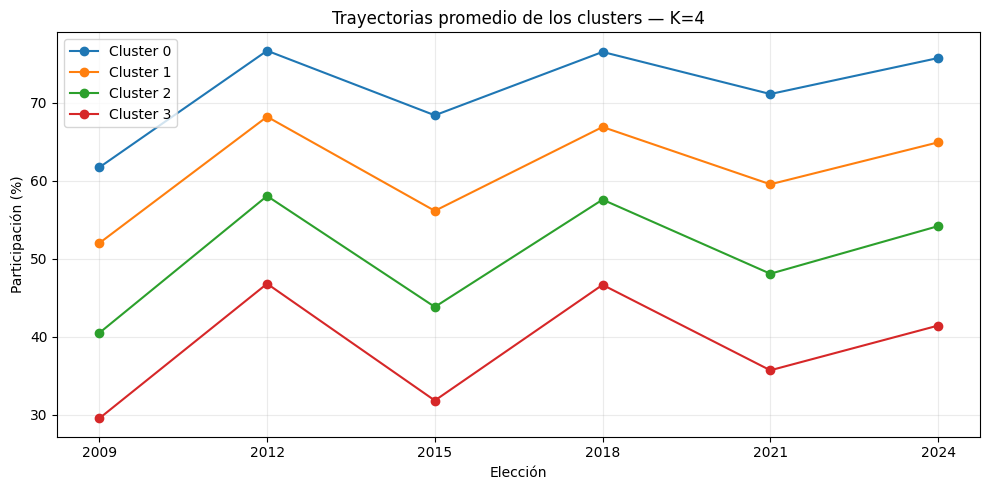

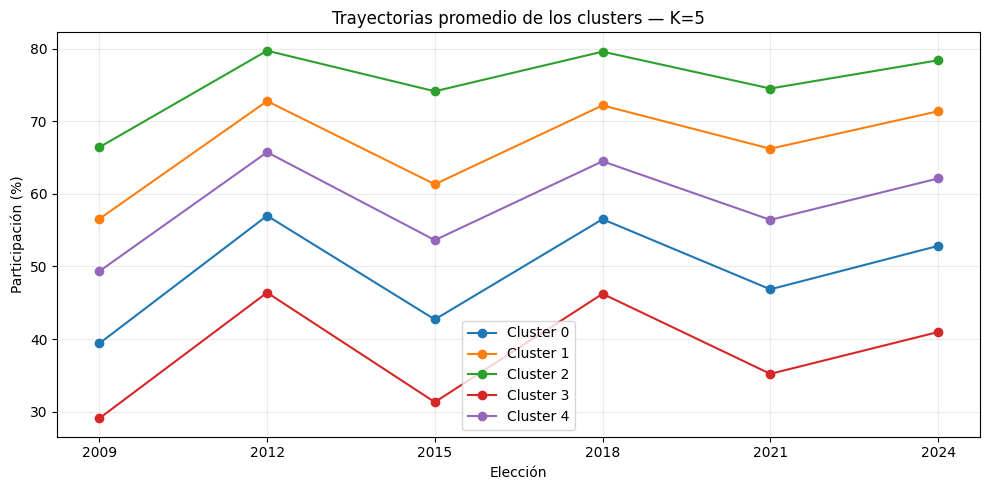

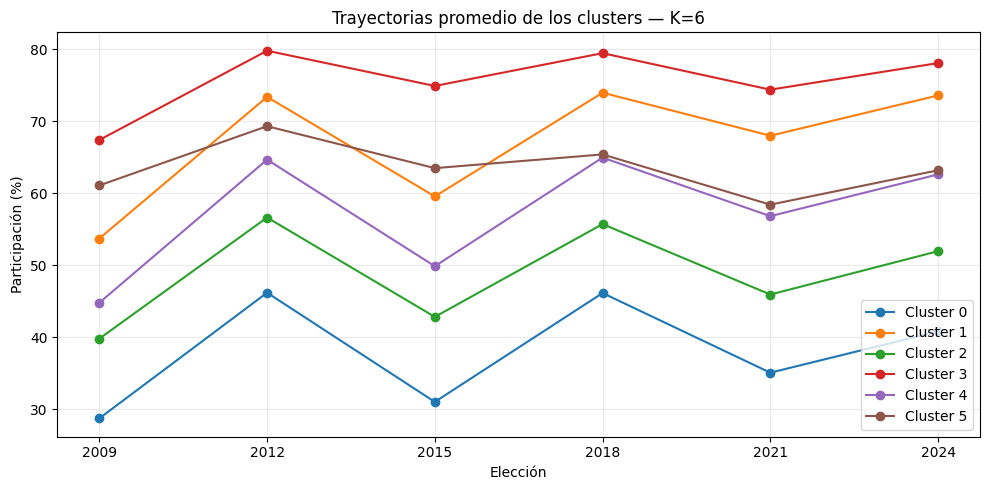

In [7]:
for k in [4, 5, 6]:
    centros = centros_por_k[k]

    plt.figure(figsize=(10, 5))

    for cluster in centros.index:
        plt.plot(
            ANIOS,
            centros.loc[cluster, PART_COLS].values,
            marker="o",
            label=f"Cluster {cluster}"
        )

    plt.xlabel("Elección")
    plt.ylabel("Participación (%)")
    plt.title(f"Trayectorias promedio de los clusters — K={k}")
    plt.xticks(ANIOS)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()


## 7. Caracterización preliminar por edad, sexo y tipo de sección

Estas variables no intervienen en K-means. Se examinan después para identificar qué características sociodemográficas aparecen con mayor frecuencia en cada conglomerado.

Se muestran proporciones dentro de cada cluster, no únicamente conteos.


In [8]:
ORDEN_EDAD = [
    "18-19", "20-24", "25-29", "30-34",
    "35-39", "40-44", "45-49", "50-54",
    "55-59", "60-64", "65-69", "70-74", "75+"
]

def tabla_porcentajes(df_in, cluster_col, variable, orden=None):
    tabla = pd.crosstab(
        df_in[cluster_col],
        df_in[variable],
        normalize="index"
    ) * 100

    if orden is not None:
        existentes = [x for x in orden if x in tabla.columns]
        tabla = tabla.reindex(columns=existentes)

    return tabla

for k in [4, 5, 6]:
    col = f"CLUSTER_K{k}"

    print(f"\n================ K = {k} ================")

    print("\nSexo (% dentro de cada cluster):")
    display(tabla_porcentajes(df, col, "SEXO_DESC").round(1))

    print("\nTipo de sección (% dentro de cada cluster):")
    display(tabla_porcentajes(df, col, "TIPOSEC_DESC").round(1))

    print("\nGrupo de edad (% dentro de cada cluster):")
    display(
        tabla_porcentajes(
            df, col, "GRUPO_EDAD", ORDEN_EDAD
        ).round(1)
    )



================ K = 4 ================

Sexo (% dentro de cada cluster):


SEXO_DESC,Hombre,Mujer
CLUSTER_K4,,
0,37.4,62.6
1,44.8,55.2
2,52.5,47.5
3,79.0,21.0



Tipo de sección (% dentro de cada cluster):


TIPOSEC_DESC,Mixta,Rural,Urbana
CLUSTER_K4,,,
0,26.5,48.6,24.9
1,35.8,29.5,34.7
2,34.0,29.1,36.8
3,38.1,23.8,38.1



Grupo de edad (% dentro de cada cluster):


...

SEXO_DESC,Hombre,Mujer
CLUSTER_K6,,
0,81.0,19.0
1,37.3,62.7
2,53.9,46.1
3,35.2,64.8
4,47.2,52.8
5,47.9,52.1



Tipo de sección (% dentro de cada cluster):


TIPOSEC_DESC,Mixta,Rural,Urbana
CLUSTER_K6,,,
0,36.7,25.7,37.6
1,31.6,32.7,35.7
2,35.3,27.6,37.1
3,25.3,59.4,15.3
4,33.2,27.5,39.3
5,35.6,39.6,24.8



Grupo de edad (% dentro de cada cluster):


GRUPO_EDAD,18-19,20-24,25-29,30-34,35-39,40-44,45-49,50-54,55-59,60-64,65-69,70-74,75+
CLUSTER_K6,,,,,,,,,,,,,
0,5.5,26.6,30.6,19.0,8.9,2.1,0.9,0.0,0.0,0.0,0.0,0.0,6.4
1,1.8,0.2,0.8,2.2,3.7,5.9,6.7,10.5,14.4,17.0,17.8,16.6,2.2
2,14.8,12.8,10.3,12.6,12.6,10.1,5.9,2.7,1.4,0.7,0.5,0.7,14.8
3,1.9,0.8,0.8,1.5,3.4,5.7,9.2,11.5,12.3,16.1,19.2,16.9,0.8
4,10.8,3.9,3.3,6.3,8.8,10.4,11.0,10.4,7.7,5.1,4.1,5.1,13.0
5,6.6,3.1,3.4,3.7,6.0,9.1,12.3,12.0,12.0,10.3,8.5,10.3,2.8


## 8. Resumen histórico derivado por cluster

Se calculan indicadores descriptivos para facilitar la interpretación de cada solución.


In [9]:
if "PROMEDIO_HIST" not in df.columns:
    df["PROMEDIO_HIST"] = df[PART_COLS].mean(axis=1)

if "STD_HIST" not in df.columns:
    df["STD_HIST"] = df[PART_COLS].std(axis=1, ddof=0)

if "CAMBIO_2009_2024" not in df.columns:
    df["CAMBIO_2009_2024"] = df["PART_2024"] - df["PART_2009"]

if "TENDENCIA_ANUAL" not in df.columns:
    def tendencia(row):
        return np.polyfit(
            ANIOS,
            [row[c] for c in PART_COLS],
            1
        )[0]

    df["TENDENCIA_ANUAL"] = df.apply(tendencia, axis=1)

for k in [4, 5, 6]:
    col = f"CLUSTER_K{k}"

    resumen = (
        df.groupby(col)
        .agg(
            UNIDADES=(col, "size"),
            PROMEDIO_HIST=("PROMEDIO_HIST", "mean"),
            VARIABILIDAD=("STD_HIST", "mean"),
            CAMBIO_2009_2024=("CAMBIO_2009_2024", "mean"),
            TENDENCIA_ANUAL=("TENDENCIA_ANUAL", "mean")
        )
    )

    print(f"\nResumen K={k}")
    display(resumen.round(3))



Resumen K=4


,UNIDADES,PROMEDIO_HIST,VARIABILIDAD,CAMBIO_2009_2024,TENDENCIA_ANUAL
CLUSTER_K4,,,,,
0,623,71.667,6.577,14.015,0.586
1,835,61.264,7.425,12.912,0.470
2,676,50.320,8.306,13.701,0.499
3,362,38.595,8.083,11.851,0.387



Resumen K=5


,UNIDADES,PROMEDIO_HIST,VARIABILIDAD,CAMBIO_2009_2024,TENDENCIA_ANUAL
CLUSTER_K5,,,,,
0,589,49.201,8.282,13.422,0.481
1,643,66.734,7.361,14.822,0.622
2,279,75.456,5.640,11.974,0.473
3,337,38.183,8.098,11.898,0.389
4,648,58.617,7.600,12.776,0.446



Resumen K=6


,UNIDADES,PROMEDIO_HIST,VARIABILIDAD,CAMBIO_2009_2024,TENDENCIA_ANUAL
CLUSTER_K6,,,,,
0,327,38.013,8.148,12.066,0.401
1,493,67.040,8.640,19.865,0.929
2,555,48.832,7.959,12.141,0.395
3,261,75.673,5.235,10.677,0.397
4,509,57.313,8.859,17.816,0.768
5,351,63.496,4.620,2.087,-0.194


## 9. Sensibilidad frente a grupos pequeños

Si la base contiene `ALGUN_GRUPO_PEQUENO`, se repite K-means después de excluir temporalmente esas unidades.

La comparación se realiza con el índice de Rand ajustado (ARI) sobre las unidades no pequeñas:

- valores cercanos a 1 indican asignaciones muy similares;
- valores próximos a 0 indican poca coincidencia respecto de lo esperable por azar.

Esto permite verificar si los grupos pequeños alteran de manera importante la estructura de los perfiles.


In [10]:
if "ALGUN_GRUPO_PEQUENO" in df.columns:
    flag = df["ALGUN_GRUPO_PEQUENO"]

    if flag.dtype == object:
        flag = (
            flag.astype(str)
            .str.strip()
            .str.lower()
            .map({"true": True, "false": False})
        )

    mascara_no_pequenos = ~flag.fillna(False)

    print("Unidades totales:", len(df))
    print("Unidades no pequeñas:", mascara_no_pequenos.sum())
    print("Unidades con al menos un año pequeño:", (~mascara_no_pequenos).sum())

    X_no_peq = df.loc[mascara_no_pequenos, PART_COLS]
    scaler_np = StandardScaler()
    X_no_peq_std = scaler_np.fit_transform(X_no_peq)

    sensibilidad = []

    for k in [4, 5, 6]:
        modelo_np = KMeans(
            n_clusters=k,
            random_state=42,
            n_init=50
        )

        labels_np = modelo_np.fit_predict(X_no_peq_std)

        labels_principal = df.loc[
            mascara_no_pequenos,
            f"CLUSTER_K{k}"
        ].values

        ari = adjusted_rand_score(
            labels_principal,
            labels_np
        )

        sil_np = silhouette_score(
            X_no_peq_std,
            labels_np
        )

        sensibilidad.append({
            "K": k,
            "ARI_VS_MODELO_COMPLETO": ari,
            "SILHOUETTE_SIN_PEQUENOS": sil_np
        })

    sensibilidad_df = pd.DataFrame(sensibilidad)

    display(
        sensibilidad_df.style.format({
            "ARI_VS_MODELO_COMPLETO": "{:.4f}",
            "SILHOUETTE_SIN_PEQUENOS": "{:.4f}"
        })
    )

else:
    print(
        "No se encontró ALGUN_GRUPO_PEQUENO. "
        "La sensibilidad no puede evaluarse en esta ejecución."
    )


Unidades totales: 2496
Unidades no pequeñas: 2470
Unidades con al menos un año pequeño: 26


,K,ARI_VS_MODELO_COMPLETO,SILHOUETTE_SIN_PEQUENOS
0,4,0.9157,0.2893
1,5,0.9980,0.2502
2,6,0.9477,0.2564


## 10. Exportación de resultados comparativos

Todavía no se asignan nombres narrativos ni se selecciona automáticamente una solución final. Primero se revisarán conjuntamente:

- silueta;
- equilibrio de tamaños;
- trayectorias de centroides;
- diferenciación sociodemográfica;
- estabilidad frente a grupos pequeños.

Después de esa revisión se elegirá la solución que se utilizará para construir los perfiles finales.


In [11]:
comparacion_k.to_csv(
    "/content/comparacion_kmeans_k4_k6.csv",
    index=False,
    encoding="utf-8-sig"
)

df.to_csv(
    "/content/asignaciones_clustering_k4_k6.csv",
    index=False,
    encoding="utf-8-sig"
)

for k, centros in centros_por_k.items():
    centros.to_csv(
        f"/content/centroides_k{k}.csv",
        encoding="utf-8-sig"
    )

print("Archivos generados:")
print(" - comparacion_kmeans_k4_k6.csv")
print(" - asignaciones_clustering_k4_k6.csv")
print(" - centroides_k4.csv")
print(" - centroides_k5.csv")
print(" - centroides_k6.csv")


Archivos generados:
 - comparacion_kmeans_k4_k6.csv
 - asignaciones_clustering_k4_k6.csv
 - centroides_k4.csv
 - centroides_k5.csv
 - centroides_k6.csv


# Próximo paso

Después de revisar las soluciones \(k=4,5,6\), se seleccionará una estructura final y se desarrollará un notebook específico para:

1. caracterizar cada perfil;
2. identificar las variables que más lo distinguen;
3. asignar nombres narrativos sustentados en los resultados;
4. generar tablas y gráficas finales;
5. preparar las fichas visuales;
6. vincular cada perfil con una estrategia diferenciada de participación.
